In [4]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 13


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        # On utilise la représentation MFCC parce que c'est rapide et efficace
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        #delta = librosa.feature.delta(mfcc)
        #delta2 = librosa.feature.delta(mfcc, order=2)

        #features = np.concatenate([summarize_feature(mfcc), summarize_feature(delta),summarize_feature(delta2)])
        features = np.concatenate([summarize_feature(mfcc)])
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None


train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)



  0%|          | 0/35549 [00:00<?, ?it/s]

  0%|          | 8/35549 [00:04<5:03:57,  1.95it/s]

  0%|          | 12/35549 [00:04<3:21:12,  2.94it/s]

  0%|          | 20/35549 [00:04<1:39:29,  5.95it/s]

  0%|          | 24/35549 [00:04<1:16:07,  7.78it/s]

  0%|          | 28/35549 [00:04<59:45,  9.91it/s]  

  0%|          | 32/35549 [00:05<47:28, 12.47it/s]

  0%|          | 36/35549 [00:05<39:02, 15.16it/s]

  0%|          | 40/35549 [00:05<33:59, 17.41it/s]

  0%|          | 44/35549 [00:05<28:44, 20.59it/s]

  0%|          | 52/35549 [00:05<22:11, 26.67it/s]

  0%|          | 56/35549 [00:05<21:52, 27.03it/s]

  0%|          | 64/35549 [00:06<20:15, 29.20it/s]

  0%|          | 72/35549 [00:06<20:05, 29.44it/s]

  0%|          | 76/35549 [00:06<19:32, 30.27it/s]

  0%|          | 80/35549 [00:06<19:15, 30.70it/s]

  0%|          | 88/35549 [00:06<17:45, 33.29it/s]

  0%|          | 92/35549 [00:06<18:16, 32.35it/s]

  0%|          | 96/35549 [00:06<17:26, 33.87it/s]

  0%|     

Extraction des features terminée !
Shape X: (32948, 120)


In [28]:
# Lorsque l'extraction des features est déja fait
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle

with open("X_mfcc.pkl", "rb") as f:
#with open("X.pkl", "rb") as f:
    X = pickle.load(f)

with open("y_mfcc.pkl", "rb") as f:
#with open("y.pkl", "rb") as f:
    y = pickle.load(f)

with open("label_encoder_mfcc.pkl", "rb") as f:
#with open("label_encoder.pkl", "rb") as f:
    le = pickle.load(f)

print("X shape:", X.shape)

X shape: (32948, 52)


In [5]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=42
)

In [53]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.030781 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 39780
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 156
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.030859 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 39780
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 156
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.1677153660246812


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [54]:
# Le code est sépararé pour améliorer la lisibilité
f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

F1-score: 0.1677153660246812


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [55]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.07107375069453162


In [87]:
from joblib import dump, load
# Sauvegarde les modèles pour éviter de refaire tous l'entraînement

""" # Les modèles uniquement avec la mfcc

dump({
    "model": model_LGBM,
    "mlb": mlb,
}, "pipeline_LGBM_mfcc.joblib")

dump({
    "model": model_forest,
    "mlb": mlb,
}, "pipeline_forest_mfcc.joblib")

"""

dump({
    "model": model_LGBM,
    "mlb": mlb,
}, "pipeline_LGBM.joblib")

dump({
    "model": model_forest,
    "mlb": mlb,
}, "pipeline_forest.joblib")



['pipeline_forest_mfcc.joblib']

In [133]:
from joblib import dump, load
# Charge les modèles pour éviter de refaire tous l'entraînement

# data = load("pipeline_LGBM_mfcc.joblib")
data = load("pipeline_LGBM.joblib")
model_LGBM = data["model"]
mlb = data["mlb"]

# data = load("pipeline_forest_mfcc.joblib")
data = load("pipeline_forest.joblib")
model_forest = data["model"]

In [ ]:
# SOUMISSION KAGGLE
proba = model.predict_proba(X_test)
submission = pd.DataFrame()

submission["row_id"] = row_ids

for i, label in enumerate(le.classes_):
    submission[label] = proba[:, i]

submission.to_csv("submission.csv", index=False)

In [ ]:
# ========================================
#       Visualisation des données
# ========================================

In [22]:
import pandas as pd

train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

print("Nombre total de fichiers :", len(train))
print("Nombre de colonnes :", train.shape[1])
print(train.head())

Nombre total de fichiers : 35549
Nombre de colonnes : 15
  primary_label secondary_labels type  latitude  longitude scientific_name  \
0       1161364               []   []  -22.7562   -46.8666    Guyalna cuta   
1       1161364               []   []  -22.7558   -46.8700    Guyalna cuta   
2       1161364               []   []  -22.7547   -46.8728    Guyalna cuta   
3       1161364               []   []  -22.7547   -46.8728    Guyalna cuta   
4       1161364               []   []  -22.7426   -46.8985    Guyalna cuta   

    common_name class_name  inat_taxon_id         author   license  rating  \
0  Guyalna cuta    Insecta        1161364  Lucas Barbosa  cc-by-nc     0.0   
1  Guyalna cuta    Insecta        1161364  Lucas Barbosa  cc-by-nc     0.0   
2  Guyalna cuta    Insecta        1161364  Lucas Barbosa  cc-by-nc     0.0   
3  Guyalna cuta    Insecta        1161364  Lucas Barbosa  cc-by-nc     0.0   
4  Guyalna cuta    Insecta        1161364  Lucas Barbosa  cc-by-nc     0.0   

     

In [23]:
# 234 d'après la description des données? (peut-être les classes qui n'ont pas beaucoup d'exemples ont été skip)
# Ou bien 234 vient des difféérentes espèces d'animaux
nb_especes = train["primary_label"].nunique()
print("Nombre d'espèces :", nb_especes)

Nombre d'espèces : 206


In [24]:
label_counts = train["primary_label"].value_counts()

print(label_counts.describe())
print("Classe la plus fréquente :", label_counts.idxmax(), label_counts.max())
print("Classe la moins fréquente :", label_counts.idxmin(), label_counts.min())

count    206.000000
mean     172.567961
std      155.371004
min        1.000000
25%       47.250000
50%      125.000000
75%      243.750000
max      499.000000
Name: count, dtype: float64
Classe la plus fréquente : rubthr1 499
Classe la moins fréquente : 516975 1


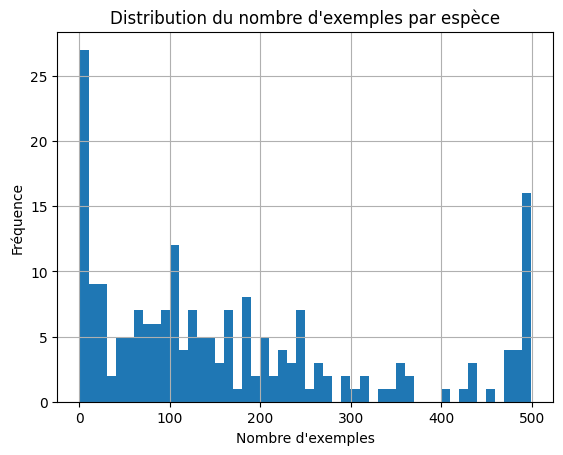

In [35]:
import matplotlib.pyplot as plt

label_counts.hist(bins=50)
plt.title("Distribution du nombre d'exemples par espèce")
plt.xlabel("Nombre d'exemples")
plt.ylabel("Fréquence")
plt.show()

In [38]:
print("Top espèces les plus fréquentes :")
print(label_counts.head(10))

# A peu près 85 espèces sur 206 possède moins de 100 exemples
print("\nTop espèces les moins fréquentes :")
print(label_counts.tail(85))

Top espèces les plus fréquentes :
primary_label
rubthr1    499
banana     498
fepowl     497
soulap1    497
houspa     496
coffal1    495
osprey     495
socfly1    494
compau     493
yeofly1    493
Name: count, dtype: int64

Top espèces les moins fréquentes :
primary_label
horscr1    102
shshaw     101
rivwar1    100
chacha1     99
swthum1     98
          ... 
209233       2
516975       1
23724        1
116570       1
23150        1
Name: count, Length: 85, dtype: int64


In [33]:
labels_df = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train_soundscapes_labels.csv")

print("Nombre de lignes soundscapes :", len(labels_df))

# nombre moyen de labels par ligne
n_labels = labels_df["primary_label"].apply(lambda x: len(x.split(";")))

print("Nombre moyen d'espèces par segment :", n_labels.mean())
print("Max espèces dans un segment :", n_labels.max())

Nombre de lignes soundscapes : 1478
Nombre moyen d'espèces par segment : 4.2246278755074425
Max espèces dans un segment : 10


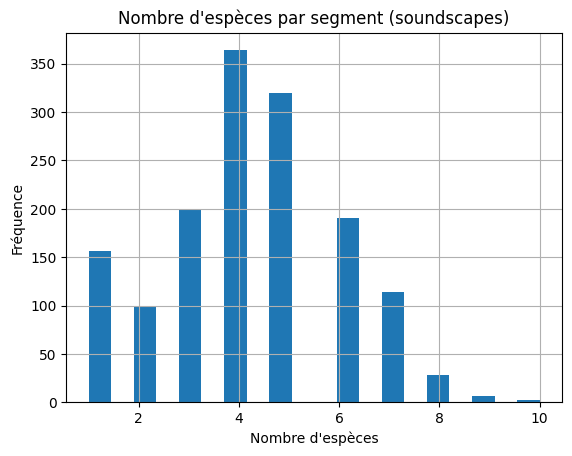

In [34]:
n_labels.hist(bins=20)
plt.title("Nombre d'espèces par segment (soundscapes)")
plt.xlabel("Nombre d'espèces")
plt.ylabel("Fréquence")
plt.show()

In [41]:
rare = (label_counts < 10).sum()
print("Nombre d'espèces avec moins de 10 exemples :", rare)
print("Proportion :", rare / nb_especes)

Nombre d'espèces avec moins de 10 exemples : 25
Proportion : 0.12135922330097088


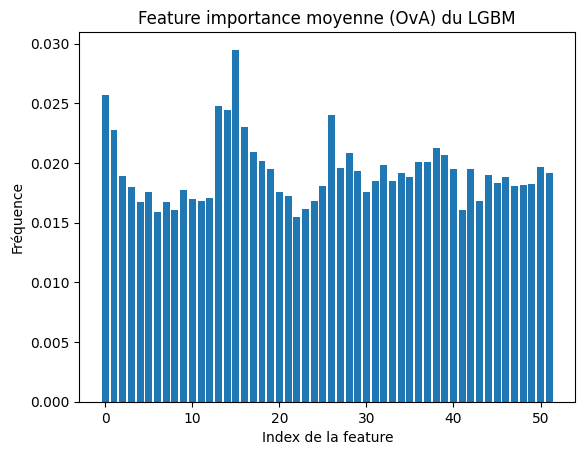

In [35]:
### Feature importance LGBM
import numpy as np
import matplotlib.pyplot as plt

model = model_LGBM


importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

# On normalise
importances = importances / np.sum(importances)


plt.bar(range(len(importances)), importances)
plt.title("Feature importance moyenne (OvA) du LGBM")
plt.xlabel("Index de la feature")
plt.ylabel("Fréquence")
plt.show()

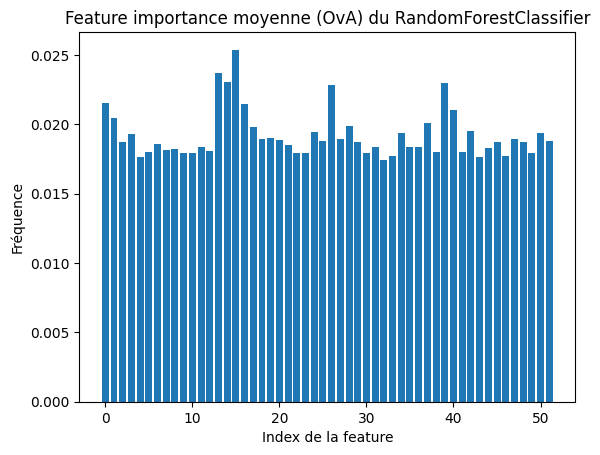

In [90]:
### Feature importance RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt

model = model_forest


importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

plt.bar(range(len(importances)), importances)
plt.title("Feature importance moyenne (OvA) du RandomForestClassifier")
plt.xlabel("Index de la feature")
plt.ylabel("Fréquence")
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Nombre de vrais : 6590
Nombre de faux : 1350950


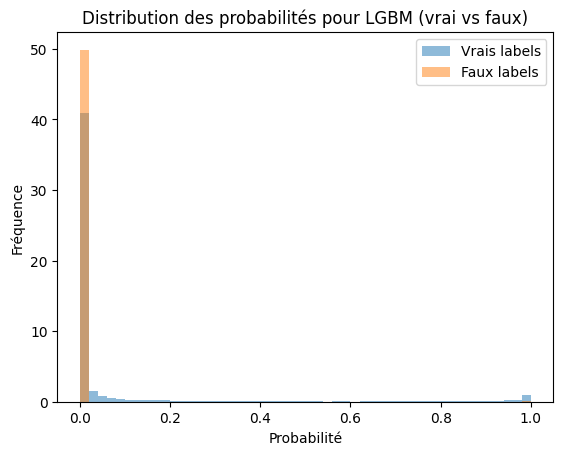

In [91]:
# Distribution des probabilités pour les vrais positifs et les faux positifs (LGBM)
import matplotlib.pyplot as plt

model = model_LGBM
y_proba = model.predict_proba(X_test)

true_probas = y_proba[y_test == 1]


print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

# Probabilités pour les faux labels (négatifs)
false_probas = y_proba[y_test == 0]

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour LGBM (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

Nombre de vrais : 6590
Nombre de faux : 1350950


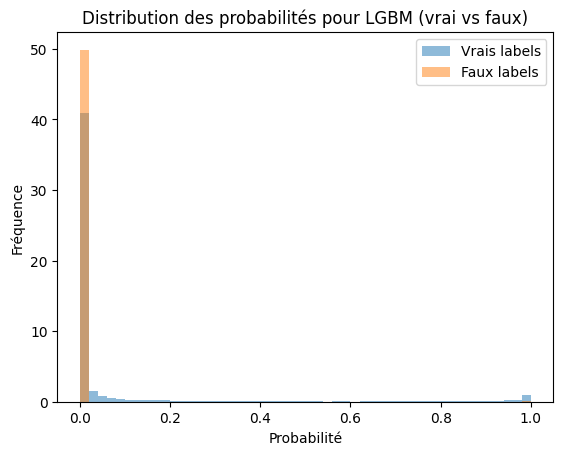

In [92]:
# Pour améliorer la lisibilité (LGBM)
print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour LGBM (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

Nombre de vrais : 6590
Nombre de faux : 1350950


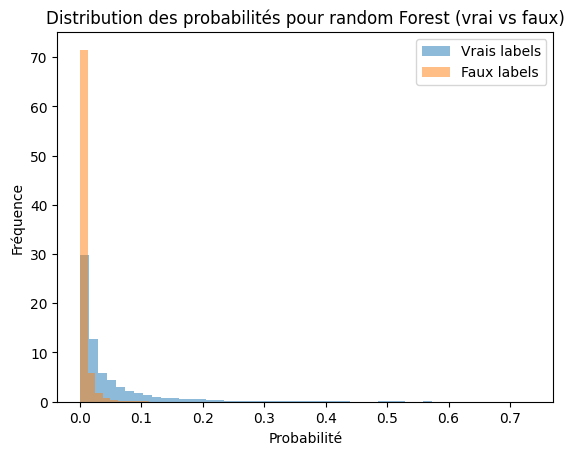

In [93]:
# Distribution des probabilités pour les vrais positifs et les faux positifs (RandomForestClassifier)
import matplotlib.pyplot as plt

model = model_forest
y_proba = model_forest.predict_proba(X_test)

true_probas = y_proba[y_test == 1]


print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

# Probabilités pour les faux labels (négatifs)
false_probas = y_proba[y_test == 0]

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour random Forest (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

In [22]:
# Pour voir quelles sont les plus grande proba
print(np.max(y_proba, axis=1)[:20])

[0.19710073 0.03512453 0.16136559 0.13855544 0.51541198 0.04560581
 0.02270431 0.02289064 0.03588625 0.02533593 0.16575753 0.04866686
 0.03682718 0.02753965 0.05130295 0.09304645 0.03525186 0.06335228
 0.12360432 0.0239175 ]


In [27]:
# Pas oublier de mettre ça dans le rapport
print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

Nombre de vrais : 6590
Nombre de faux : 1350950


Vérifie que la somme est égale à 1 :  0.9999999999999999
mean 0.018743260284886896
std 0.020138121982486025
min 0.01948515255644275
max 0.01855654209926124


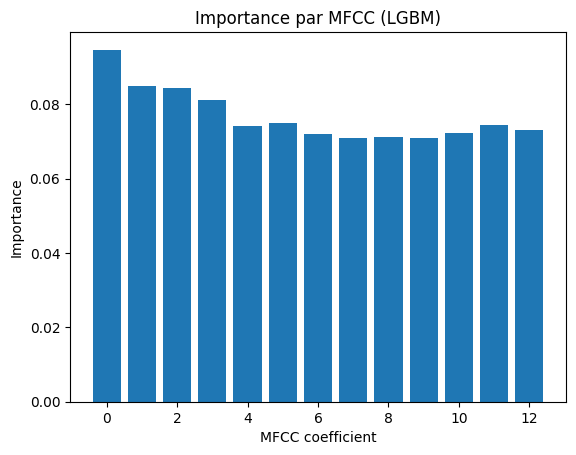

In [94]:
# Visualisation de l'importance de la MFCC (LGBM)
import numpy as np
import matplotlib.pyplot as plt

model = model_LGBM

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 13
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

Vérifie que la somme est égale à 1 :  1.0
mean 0.018700539316997153
std 0.020234765557237466
min 0.01892954457549922
max 0.01905822747334309


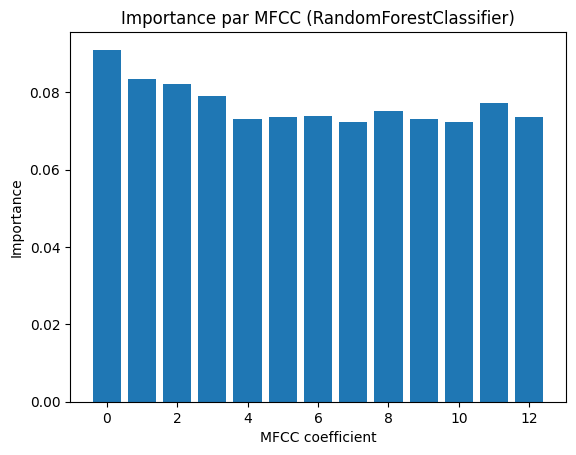

In [95]:
# Visualisation de l'importance de la MFCC (RandomForestClassifier)
import numpy as np
import matplotlib.pyplot as plt

model = model_forest

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 13
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (RandomForestClassifier)")
plt.show()

In [96]:
# Permet de trouver les features les plus interréssantes
import numpy as np
top_n = 10

model = model_forest
importances = np.mean(
        [est.feature_importances_ for est in model.estimators_],
        axis=0
    )

indices = np.argsort(importances)[::-1][:top_n]

rf_idx, rf_imp = indices, importances[indices]

#####


model = model_LGBM
importances = np.mean(
        [est.feature_importances_ for est in model.estimators_],
        axis=0
    )

indices = np.argsort(importances)[::-1][:top_n]

lgbm_idx, lgbm_imp = indices, importances[indices]
lgbm_imp = lgbm_imp / np.sum(importances)

#####

print("Top index RandomForest:", rf_idx)
print("Top importance RandomForest:", rf_imp)
print("\nTop index LGBM:", lgbm_idx)
print("Top importance LGBM:", lgbm_imp)
commun = set(rf_idx).intersection(set(lgbm_idx))
print("\nFeatures communes:", common)
print("Tailles des features en commun : ", len(commun))

Top index RandomForest: [15 13 14 39 26  0 16 40  1 37]
Top importance RandomForest: [0.02538531 0.02370403 0.0230639  0.02297267 0.02284265 0.02151927
 0.02150371 0.02105408 0.02042588 0.02010756]

Top index LGBM: [15  0 14 13 26 16  1 39 17 28]
Top importance LGBM: [0.02937716 0.02582255 0.02476046 0.02445474 0.02303118 0.02296386
 0.02210115 0.02142539 0.02081481 0.02026725]

Features communes: {np.int64(0), np.int64(1), np.int64(39), np.int64(13), np.int64(15), np.int64(26)}
Tailles des features en commun :  8


In [99]:
# Permet de retrouver à quelle feature correspond l'index
def decode_feature(idx, n_mfcc=13):
    block = idx // n_mfcc
    mfcc_id = idx % n_mfcc

    types = ["mean", "std", "min", "max"]
    return print(types[block], "MFCC", mfcc_id)

"""def decode_feature(idx, n_mfcc=13):
    n = idx%n_mfcc

    if idx < n_mfcc:
        return print("\t mean MFCC", n, idx)
    elif idx < 2*n_mfcc:
        return print("\t std MFCC", n, idx - n_mfcc)
    elif idx < 3*n_mfcc:
        return print("\t min MFCC", n, idx - 2*n_mfcc)
    else:
        return print("\t max MFCC", n, idx - 3*n_mfcc)
"""



print("RF:")
for i in rf_idx:
    decode_feature(i)

print("\nLGBM:") 
for i in lgbm_idx:
    decode_feature(i)




RF:
std MFCC 2
std MFCC 0
std MFCC 1
max MFCC 0
min MFCC 0
mean MFCC 0
std MFCC 3
max MFCC 1
mean MFCC 1
min MFCC 11

LGBM:
std MFCC 2
mean MFCC 0
std MFCC 1
std MFCC 0
min MFCC 0
std MFCC 3
mean MFCC 1
max MFCC 0
std MFCC 4
min MFCC 2


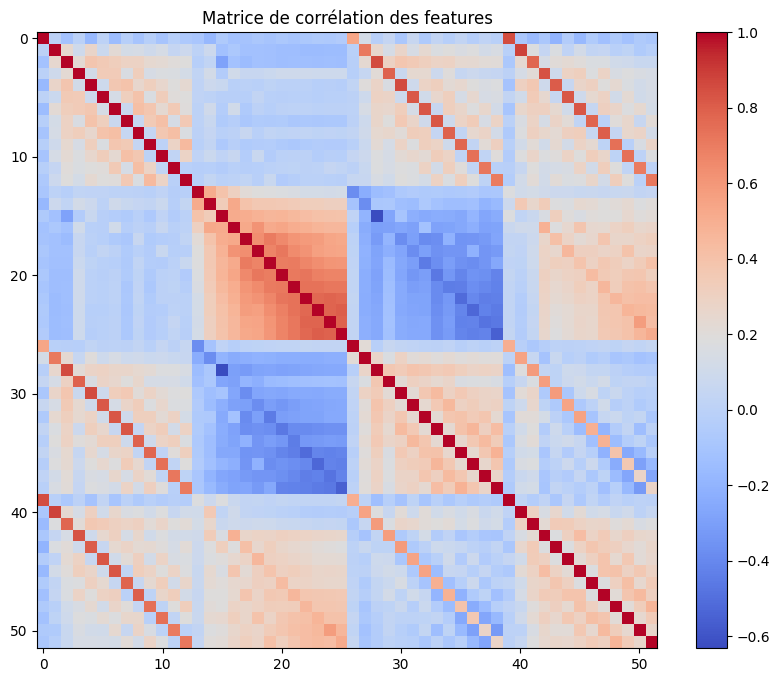

In [122]:
import numpy as np
import pandas as pd

# convertir en DataFrame pour plus de lisibilité
df = pd.DataFrame(X)

corr_matrix = df.corr()

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.title("Matrice de corrélation des features")
plt.show()

In [113]:
# Détermine les paires correlées
threshold = 0.80

corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            corr_pairs.append((i, j, corr_matrix.iloc[i, j]))

print("Paires corrélées :", corr_pairs[:20])
print("Nombre de paires corrélées :", len(corr_pairs))

Paires corrélées : [(28, 2, np.float64(0.8564831758385717)), (30, 4, np.float64(0.8561630122857541)), (31, 5, np.float64(0.8156033570659251)), (32, 6, np.float64(0.8227636084397862)), (33, 7, np.float64(0.8232416626958574)), (39, 0, np.float64(0.8520353344570882)), (40, 1, np.float64(0.8790597144712666)), (42, 3, np.float64(0.8363045336446544)), (43, 4, np.float64(0.8070729000043646)), (44, 5, np.float64(0.8238314094811915)), (45, 6, np.float64(0.82216138973729))]
Nombre de paires corrélées : 11


In [125]:
# On voit les résultats en supprimant les features redondantes
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42
)


import pandas as pd
df_train = pd.DataFrame(X_train)
df_test = pd.DataFrame(X_test)

# On supprime les features redondantes
corr_matrix = df_train.corr()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [col for col in upper.columns if any(abs(upper[col]) > 0.8)]

# nouvelle données
X_train_reduced = df_train.drop(columns=to_drop).values
X_test_reduced = df_test.drop(columns=to_drop).values

print(X_train_reduced.shape)
print(y_train.shape)

(26358, 40)
(26358, 206)


In [126]:
# Environ 10 min
model_LGBM_nouveau = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM_nouveau.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM_nouveau.predict(X_test)

f1_LGBM_nouveau = f1_score(y_test, y_pred, average="macro")
print("Nouveau F1-score:", f1_LGBM_nouveau)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010542 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Nouveau F1-score: 0.07613554990419023


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [127]:
f1_LGBM_nouveau = f1_score(y_test, y_pred, average="macro")
print("Nouveau F1-score:", f1_LGBM_nouveau)

Nouveau F1-score: 0.07613554990419023


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [128]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=10, max_depth=5, n_jobs=-1))
# 1h
model_forest_nouveau = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))

print("Entraînement...")
model_forest_nouveau.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest_nouveau.predict(X_test)

f1_forest_nouveau = f1_score(y_test, y_pred, average="macro")
print("Nouveau F1-score:", f1_forest_nouveau)



Modele...
Entraînement...
Predictions
Nouveau F1-score: 0.01195801372133767


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [131]:
from joblib import dump, load
# Sauvegarde les modèles pour éviter de refaire tous l'entraînement
dump({
    "model": model_LGBM_nouveau,
    "mlb": mlb,
}, "pipeline_LGBM_mfcc_supp.joblib")

dump({
    "model": model_forest_nouveau,
    "mlb": mlb,
}, "pipeline_forest_mfcc_supp.joblib")

['pipeline_forest_mfcc_supp.joblib']

In [ ]:
from joblib import dump, load
# Charge les modèles pour éviter de refaire tous l'entraînement

# data = load("pipeline_LGBM_mfcc_supp.joblib")
data = load("pipeline_LGBM_supp.joblib")
model_LGBM_nouveau = data["model"]
mlb = data["mlb"]

# data = load("pipeline_forest_mfcc_supp.joblib")
data = load("pipeline_forest_supp.joblib")
model_forest_nouveau = data["model"]

In [ ]:
# ===========================================
#      Analyse avec delta et delta 2
#============================================

In [73]:
n_mfcc = 13
block = 4 * n_mfcc  # mean/std/min/max pour 1 type

groups = {
    "mfcc": importances[:block],
    "delta": importances[block:2*block],
    "delta2": importances[2*block:3*block]
}

for k, v in groups.items():
    print(k, np.sum(v))

labels = ["mfcc", "delta", "delta2"]
values = [np.sum(groups[k]) for k in labels]

plt.bar(labels, values)
plt.title("Importance par type de feature")
plt.show()

mfcc 4522.898058252427
delta 3438.0242718446602
delta2 3244.9223300970875


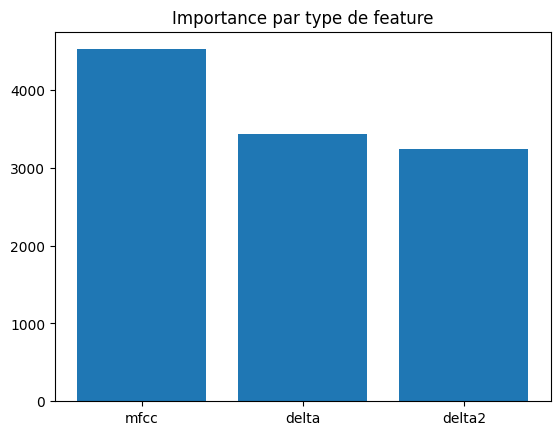

In [74]:
labels = ["mfcc", "delta", "delta2"]
values = [np.sum(groups[k]) for k in labels]

plt.bar(labels, values)
plt.title("Importance par type de feature")
plt.show()

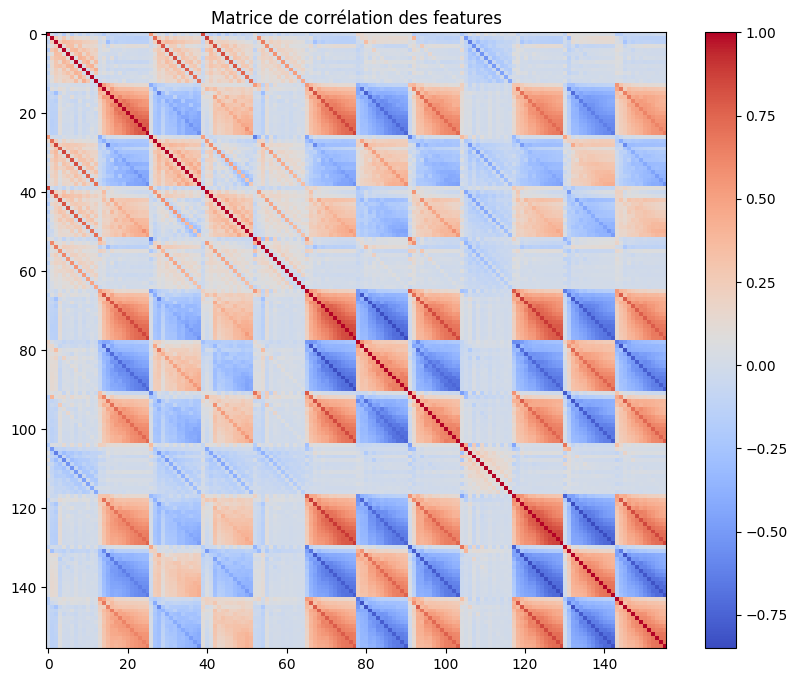

In [138]:
import numpy as np
import pandas as pd

# convertir en DataFrame pour plus de lisibilité
df = pd.DataFrame(X)

corr_matrix = df.corr()

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.title("Matrice de corrélation des features")
plt.show()

In [139]:
# Détermine les paires correlées
threshold = 0.80

corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            corr_pairs.append((i, j, corr_matrix.iloc[i, j]))

print("Paires corrélées :", corr_pairs[:20])
print("Nombre de paires corrélées :", len(corr_pairs))

Paires corrélées : [(28, 2, np.float64(0.8564831758385717)), (30, 4, np.float64(0.8561630122857541)), (31, 5, np.float64(0.8156033570659251)), (32, 6, np.float64(0.8227636084397862)), (33, 7, np.float64(0.8232416626958574)), (39, 0, np.float64(0.8520353344570882)), (40, 1, np.float64(0.8790597144712666)), (42, 3, np.float64(0.8363045336446544)), (43, 4, np.float64(0.8070729000043646)), (44, 5, np.float64(0.8238314094811915)), (45, 6, np.float64(0.82216138973729)), (66, 14, np.float64(0.8184031807311434)), (67, 15, np.float64(0.8181954192598011)), (68, 16, np.float64(0.8167442301526572)), (69, 17, np.float64(0.8178162301855946)), (70, 18, np.float64(0.8238199132082116)), (71, 19, np.float64(0.827368476521128)), (72, 20, np.float64(0.8350652160656075)), (73, 21, np.float64(0.8460053708666074)), (73, 72, np.float64(0.8039275581257008))]
Nombre de paires corrélées : 114


In [140]:
# On voit les résultats en supprimant les features redondantes
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42
)


import pandas as pd
df_train = pd.DataFrame(X_train)
df_test = pd.DataFrame(X_test)

# On supprime les features redondantes
corr_matrix = df_train.corr()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [col for col in upper.columns if any(abs(upper[col]) > 0.8)]

# nouvelle données
X_train_reduced = df_train.drop(columns=to_drop).values
X_test_reduced = df_test.drop(columns=to_drop).values

print(X_train_reduced.shape)
print(y_train.shape)

(26358, 74)
(26358, 206)


In [141]:
# Environ 25 min
model_LGBM_nouveau = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM_nouveau.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM_nouveau.predict(X_test)

f1_LGBM_nouveau = f1_score(y_test, y_pred, average="macro")
print("Nouveau F1-score:", f1_LGBM_nouveau)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.038508 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 39780
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 156
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 1, number of negative: 26357
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.033726 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 39780
[Li

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Nouveau F1-score: 0.08135664073899689


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [142]:
print("Nouveau F1-score:", f1_LGBM_nouveau)

Nouveau F1-score: 0.08135664073899689


In [143]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=10, max_depth=5, n_jobs=-1))
# 1h
model_forest_nouveau = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))

print("Entraînement...")
model_forest_nouveau.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest_nouveau.predict(X_test)

f1_forest_nouveau = f1_score(y_test, y_pred, average="macro")
print("Nouveau F1-score:", f1_forest_nouveau)



Modele...
Entraînement...
Predictions
Nouveau F1-score: 0.011222179970018467


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [144]:
from joblib import dump, load
# Sauvegarde les modèles pour éviter de refaire tous l'entraînement
dump({
    "model": model_LGBM_nouveau,
    "mlb": mlb,
}, "pipeline_LGBM_delta_supp.joblib")

dump({
    "model": model_forest_nouveau,
    "mlb": mlb,
}, "pipeline_forest_delta_supp.joblib")

['pipeline_forest_delta_supp.joblib']

In [ ]:
from joblib import dump, load
# Charge les modèles pour éviter de refaire tous l'entraînement

# data = load("pipeline_LGBM_mfcc.joblib")
data = load("pipeline_LGBM_delta_supp.joblib")
model_LGBM_nouveau = data["model"]
mlb = data["mlb"]

# data = load("pipeline_forest_mfcc.joblib")
data = load("pipeline_forest_delta_supp.joblib")
model_forest_nouveau = data["model"]

In [ ]:
# ==================================
#      Clustering des features
# ==================================

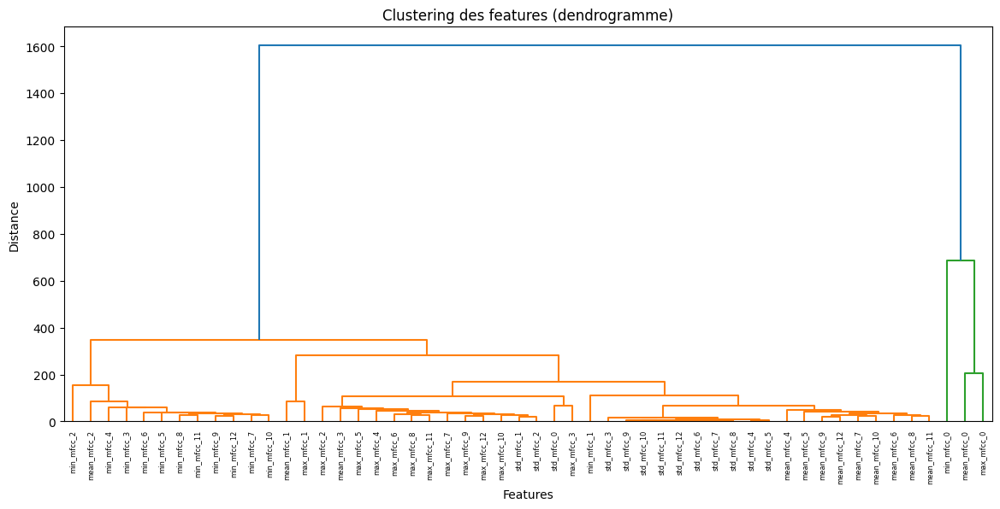

In [22]:
# Cluster des features
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt


def types_feature(n_mfcc=13):
    names = []
    types = ["mean", "std", "min", "max"]

    for t in types:
        for i in range(n_mfcc):
            names.append(f"{t}_mfcc_{i}")

    return names



# pour transfo les features en samples
X_t = X.T

X_t_scaled = StandardScaler().fit_transform(X_t)

Z = linkage(X_t_scaled, method="ward")

types = types_feature()

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=types, leaf_rotation=90)
plt.title("Clustering des features (dendrogramme)")
plt.xlabel("Features")
plt.ylabel("Distance")
plt.show()

In [21]:
# Retrouver les features
from scipy.cluster.hierarchy import fcluster

clusters = fcluster(Z, t=2, criterion="maxclust")

for i in range(1, 3):
    print(f"Cluster {i}:")
    for j, c in enumerate(clusters):
        if c == i:
            print(names[j])
    print()

Cluster 1:
mean_mfcc_1
mean_mfcc_2
mean_mfcc_3
mean_mfcc_4
mean_mfcc_5
mean_mfcc_6
mean_mfcc_7
mean_mfcc_8
mean_mfcc_9
mean_mfcc_10
mean_mfcc_11
mean_mfcc_12
std_mfcc_0
std_mfcc_1
std_mfcc_2
std_mfcc_3
std_mfcc_4
std_mfcc_5
std_mfcc_6
std_mfcc_7
std_mfcc_8
std_mfcc_9
std_mfcc_10
std_mfcc_11
std_mfcc_12
min_mfcc_1
min_mfcc_2
min_mfcc_3
min_mfcc_4
min_mfcc_5
min_mfcc_6
min_mfcc_7
min_mfcc_8
min_mfcc_9
min_mfcc_10
min_mfcc_11
min_mfcc_12
max_mfcc_1
max_mfcc_2
max_mfcc_3
max_mfcc_4
max_mfcc_5
max_mfcc_6
max_mfcc_7
max_mfcc_8
max_mfcc_9
max_mfcc_10
max_mfcc_11
max_mfcc_12

Cluster 2:
mean_mfcc_0
min_mfcc_0
max_mfcc_0



In [1]:
# Extraction des features cette fois uniquement avec les mfcc de 0 à 4 pour voir si il ya une grosse différence
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 4


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        # On utilise la représentation MFCC parce que c'est rapide et efficace
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        #delta = librosa.feature.delta(mfcc)
        
        #features = np.concatenate([summarize_feature(mfcc), summarize_feature(delta)])
        features = np.concatenate([summarize_feature(mfcc)])
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None



train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc_03.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc_03.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc_03.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [15:11<00:00, 39.00it/s]


Extraction des features terminée !
Shape X: (32948, 52)


In [25]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=42
)

In [26]:
### Model LGBM


# Environ 23 min
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006422 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8160
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 32
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 1, number of negative: 26357
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005182 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8160
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 32
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000038 -> ini

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.04591554077368877


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [27]:
# Même pas envie de tester les résultats sont mauvais
print("F1-score:", f1_LGBM)

F1-score: 0.04591554077368877


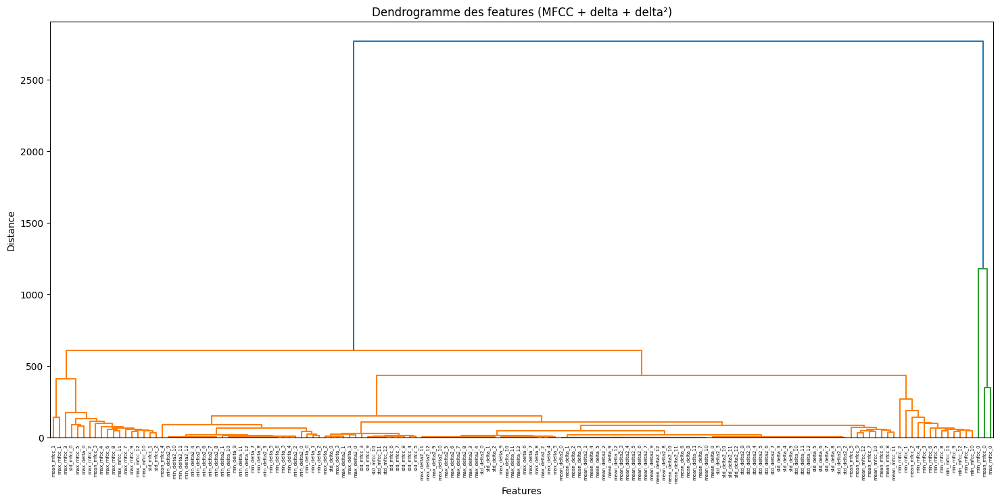

In [42]:
# Dendrogramme pour mfcc, delta, et delat^2
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt


def feature_names(n_mfcc=13):
    names = []
    stats = ["mean", "std", "min", "max"]
    types = ["mfcc", "delta", "delta2"]

    for t in types:
        for s in stats:
            for i in range(n_mfcc):
                names.append(f"{s}_{t}_{i}")

    return names


def extract_full_features(y, sr, n_mfcc=13):

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    def summarize(f):
        return np.concatenate([
            np.mean(f, axis=1),
            np.std(f, axis=1),
            np.min(f, axis=1),
            np.max(f, axis=1)
        ])

    return np.concatenate([
        summarize(mfcc),
        summarize(delta),
        summarize(delta2)
    ])





# pour transfo les features en sample
X_t = X.T

# normalisation
X_t_scaled = StandardScaler().fit_transform(X_t)

# clustering hiérarchique
Z = linkage(X_t_scaled, method="ward")

# noms des features
names = feature_names(n_mfcc=13)

# dendrogramme
plt.figure(figsize=(18, 8))
dendrogram(Z, labels=names, leaf_rotation=90)

plt.title("Dendrogramme des features (MFCC + delta + delta²)")
plt.xlabel("Features")
plt.ylabel("Distance")

plt.show()

In [ ]:
# ==============================================================
#   découper les audio en 2 segments pour doubler les features
# ==============================================================

In [62]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 13


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # garder 5 secondes
        y = y[:sr * DURATION]

        if len(y) < sr * DURATION:
            return None

        # séparation en deux segment
        half = len(y) // 2
        segments = [
            y[:half],
            y[half:]
        ]

        feats = []

        for seg in segments:
            mfcc = librosa.feature.mfcc(y=seg, sr=sr, n_mfcc=N_MFCC)

            # je vais tester delta si c'est pas trop long
            # delta = librosa.feature.delta(mfcc)

            feats.append(np.concatenate([summarize_feature(mfcc)]))

        # concaténer les 2 segments pour plus d'information (on l'espère)
        return np.concatenate(feats)

    except:
        return None



train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [13:57<00:00, 42.44it/s]


Extraction des features terminée !
Shape X: (32948, 104)


In [71]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec les seeds 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=7
)

In [72]:
### Model LGBM


# Environ 23 min
"""
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)
"""

model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.019098 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26520
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 104
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022070 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26520
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 104
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.13696305253655155


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [73]:
print("F1-score:", f1_LGBM)

F1-score: 0.13696305253655155


In [75]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)

Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.06132670372862844


In [ ]:
# ======================
#         Seuil
# ======================

In [44]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=42
)

In [3]:
### Model LGBM


# Environ 23 min
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010989 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.07569424363764123


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [4]:
f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

F1-score: 0.07569424363764123


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Meilleur seuil: 0.01
meilleur F1: 0.15720675835425066


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


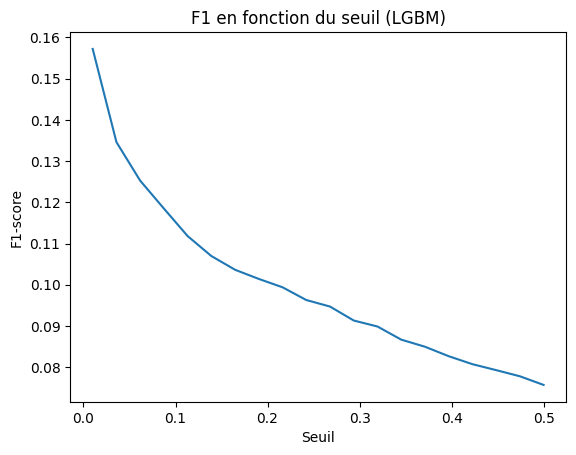

In [14]:
# Déterminer le meilleur seuil pour f1 (on met le seuil sur les données de test pour éviter la fuite de données)
# Sur LGBM
import matplotlib.pyplot as plt
best_f1 = 0
best_t = 0
f1_scores = []
seuils = np.linspace(0.01, 0.5, 20)

y_proba = model_LGBM.predict_proba(X_test)

for t in seuils:
    y_pred = (y_proba > t).astype(int)
    f1 = f1_score(y_test, y_pred, average="macro")
    f1_scores.append(f1)

    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (LGBM)")
plt.show()

Meilleur seuil: 0.01
meilleur F1: 0.15720675835425066


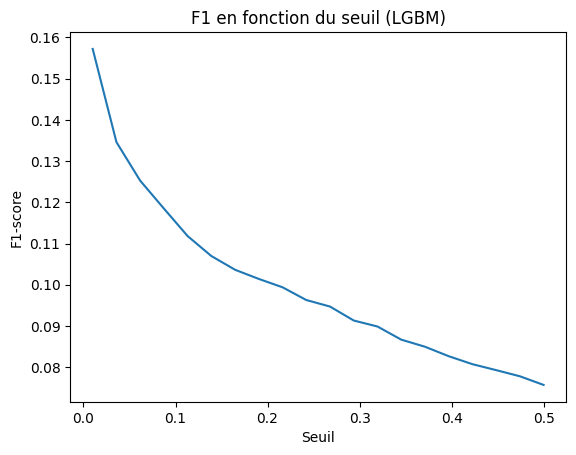

In [15]:
# Toujours LGBM
print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (LGBM)")
plt.show()

In [7]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=10, max_depth=5, n_jobs=-1))
# 1h
model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.012497385161822645


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/di

Meilleur seuil: 0.08736842105263157
meilleur F1: 0.1251014983028406


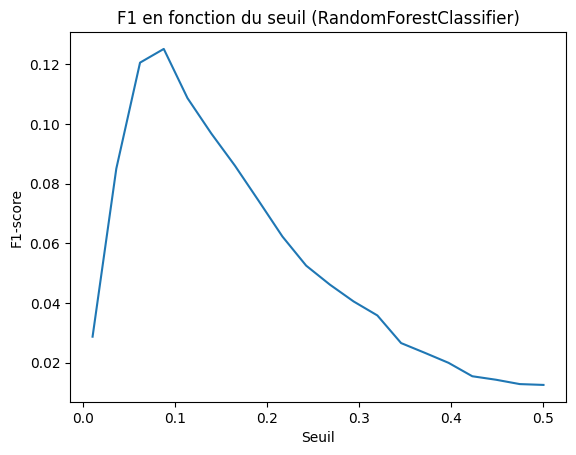

In [16]:
# Déterminer le meilleur seuil pour f1 (on met le seuil sur les données de test pour éviter la fuite de données)
# Sur RandomForestClassifier
import matplotlib.pyplot as plt
best_f1 = 0
best_t = 0
f1_scores = []
seuils = np.linspace(0.01, 0.5, 20)

y_proba = model_forest.predict_proba(X_test)

for t in seuils:
    y_pred = (y_proba > t).astype(int)
    f1 = f1_score(y_test, y_pred, average="macro")
    f1_scores.append(f1)

    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (RandomForestClassifier)")
plt.show()

In [10]:
# Toujours RandomForestClassifier
print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

Meilleur seuil: 0.1
meilleur F1: 0.11828947769255135


In [ ]:
# ========================================================
# On retente de séparé les audios avec une sliding window
# ========================================================

In [104]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 13


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        y, sr = sf.read(path)

        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        y = y[:sr * DURATION]

        if len(y) < sr * DURATION:
            return None

        # Cette fois on va faire en sorte que les deux segments aient des une partie en commun pour ne pas trop casser la structure de l'audio
        window_size = int(2 * sr)   # 2 secondes
        hop_size = int(1 * sr)      # overlap 50%

        feats = []

        for start in range(0, len(y) - window_size + 1, hop_size):
            segment = y[start:start + window_size]

            mfcc = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=N_MFCC)
            #delta = librosa.feature.delta(mfcc)

            feats.append(np.concatenate([summarize_feature(mfcc)]))

        # 👉 au lieu de concat → MOYENNE
        return np.mean(feats, axis=0)

    except:
        return None



train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [17:17<00:00, 34.26it/s]


Extraction des features terminée !
Shape X: (32948, 52)


In [87]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=7
)

In [88]:
### Model LGBM


# Environ 23 min
"""
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)
"""

model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009006 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008451 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.15433106053514503


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [89]:
print("F1-score:", f1_LGBM)

F1-score: 0.15433106053514503


In [90]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)

Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.059444254953130514


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Meilleur seuil: 0.01
meilleur F1: 0.16918480353733864


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


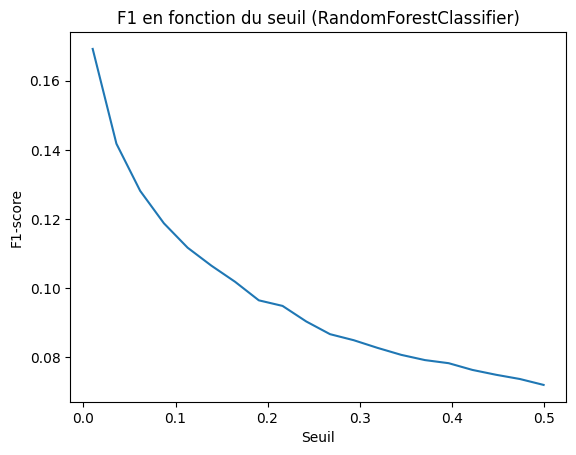

In [6]:
# Déterminer le meilleur seuil pour f1 (on met le seuil sur les données de test pour éviter la fuite de données)
# Sur RandomForestClassifier
import matplotlib.pyplot as plt
best_f1 = 0
best_t = 0
f1_scores = []
seuils = np.linspace(0.01, 0.5, 20)

y_proba = model_LGBM.predict_proba(X_test)

for t in seuils:
    y_pred = (y_proba > t).astype(int)
    f1 = f1_score(y_test, y_pred, average="macro")
    f1_scores.append(f1)

    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (RandomForestClassifier)")
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/di

Meilleur seuil: 0.01
meilleur F1: 0.16918480353733864


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


ValueError: x and y must have same first dimension, but have shapes (20,) and (40,)

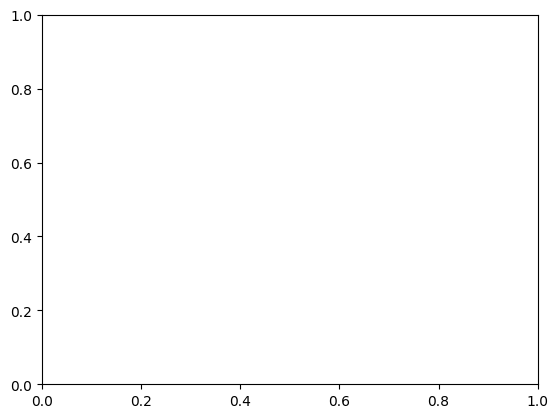

In [8]:
for t in seuils:
    y_pred = (y_proba > t).astype(int)
    f1 = f1_score(y_test, y_pred, average="macro")
    f1_scores.append(f1)

    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (RandomForestClassifier)")
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/di

Meilleur seuil: 0.08736842105263157
meilleur F1: 0.1169935138687247


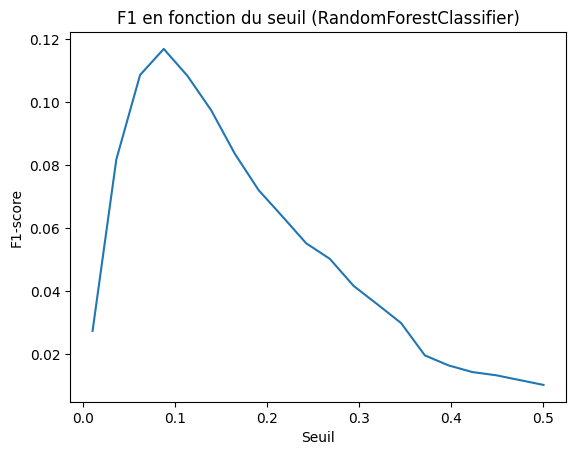

In [9]:
# Déterminer le meilleur seuil pour f1 (on met le seuil sur les données de test pour éviter la fuite de données)
# Sur RandomForestClassifier
import matplotlib.pyplot as plt
best_f1 = 0
best_t = 0
f1_scores = []
seuils = np.linspace(0.01, 0.5, 20)

y_proba = model_forest.predict_proba(X_test)

for t in seuils:
    y_pred = (y_proba > t).astype(int)
    f1 = f1_score(y_test, y_pred, average="macro")
    f1_scores.append(f1)

    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print("Meilleur seuil:", best_t)
print("meilleur F1:", best_f1)

plt.plot(seuils, f1_scores)
plt.xlabel("Seuil")
plt.ylabel("F1-score")
plt.title("F1 en fonction du seuil (RandomForestClassifier)")
plt.show()

In [ ]:
# =============
# Avec 20 mfcc
# =============

In [10]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 20


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        # On utilise la représentation MFCC parce que c'est rapide et efficace
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        #delta = librosa.feature.delta(mfcc)
        #delta2 = librosa.feature.delta(mfcc, order=2)

        #features = np.concatenate([summarize_feature(mfcc), summarize_feature(delta),summarize_feature(delta2)])
        features = np.concatenate([summarize_feature(mfcc)])
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None



train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [14:23<00:00, 41.17it/s]


Extraction des features terminée !
Shape X: (32948, 0)


In [11]:
### Model LGBM


# Environ 23 min
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014473 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26520
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 104
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 1, number of negative: 26357
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014287 seconds.
You can set `force_co

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.07200259802420474


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
print("F1-score:", f1_LGBM)

F1-score: 0.07200259802420474


In [13]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=10, max_depth=5, n_jobs=-1))
# 1h
model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.011044501050886026


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Vérifie que la somme est égale à 1 :  1.0
mean 0.009809163161378663
std 0.010431297980887318
min 0.009211893895113194
max 0.009009183424159285


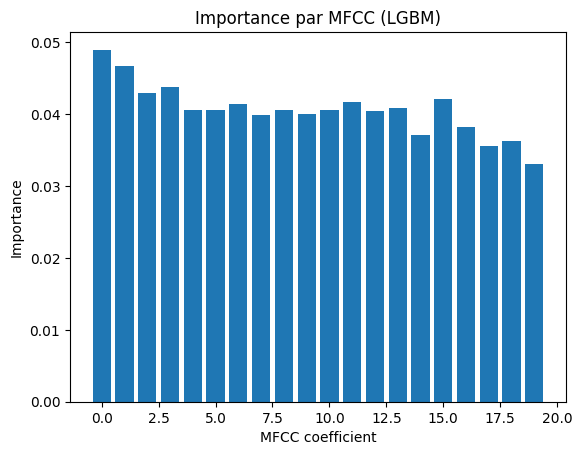

In [18]:
# Visualisation de l'importance de la MFCC (LGBM)
import numpy as np
import matplotlib.pyplot as plt

model = model_LGBM

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 20
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

Vérifie que la somme est égale à 1 :  1.0
mean 0.009671196980141971
std 0.009845710169609381
min 0.009585066511660897
max 0.00935956480012621


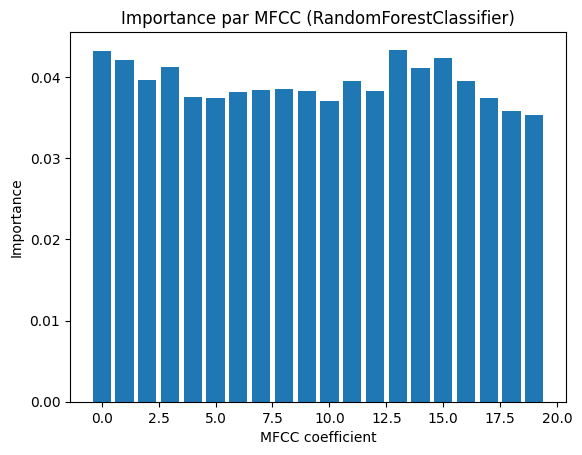

In [14]:
# Visualisation de l'importance de la MFCC (RandomForestClassifier)
import numpy as np
import matplotlib.pyplot as plt

model = model_forest

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 20
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (RandomForestClassifier)")
plt.show()

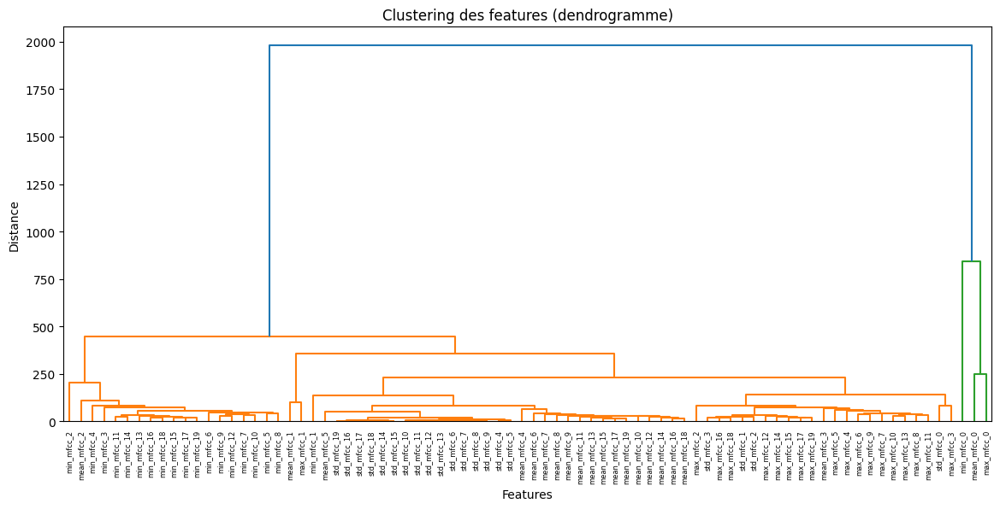

In [20]:
# Cluster des features
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt


def types_feature(n_mfcc=20):
    names = []
    types = ["mean", "std", "min", "max"]

    for t in types:
        for i in range(n_mfcc):
            names.append(f"{t}_mfcc_{i}")

    return names



# pour transfo les features en samples
X_t = X.T

X_t_scaled = StandardScaler().fit_transform(X_t)

Z = linkage(X_t_scaled, method="ward")

types = types_feature()

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=types, leaf_rotation=90)
plt.title("Clustering des features (dendrogramme)")
plt.xlabel("Features")
plt.ylabel("Distance")
plt.show()

In [ ]:
# ==============
# Mel Spectrogram
# ==============

In [91]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 13


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        mel = librosa.feature.melspectrogram(y=y, sr=sr)
        mel_db = librosa.power_to_db(mel)
        features = summarize_feature(mel_db)
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None



train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [13:36<00:00, 43.56it/s]


Extraction des features terminée !
Shape X: (32948, 512)


In [99]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=13
)

In [96]:
### Model LGBM


# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))


print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.347890 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 130560
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 512
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.16387210098030722


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [97]:
print("F1-score:", f1_LGBM)

F1-score: 0.16387210098030722


In [103]:
print(np.max(y_proba, axis=1)[:20])

# Distribution des probabilités pour les vrais positifs et les faux positifs (LGBM)
import matplotlib.pyplot as plt

model = model_LGBM
y_proba = model.predict_proba(X_test)

true_probas = y_proba[y_test == 1]


print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

# Probabilités pour les faux labels (négatifs)
false_probas = y_proba[y_test == 0]

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour LGBM (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

NameError: name 'y_proba' is not defined

In [100]:
print(np.max(y_proba, axis=1)[:20])
plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour LGBM (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

NameError: name 'y_proba' is not defined

In [102]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)

Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.05955809071867126


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

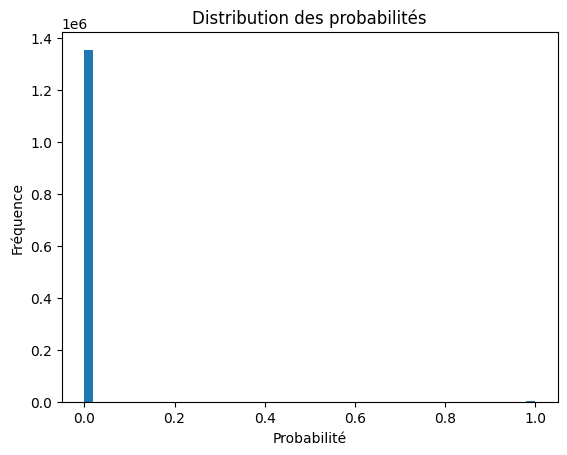

Mean: 0.0017802007108313536
Std: 0.03929265132690487


In [53]:
import matplotlib.pyplot as plt
import numpy as np
model = model_LGBM

y_prob = model.predict_proba(X_test)

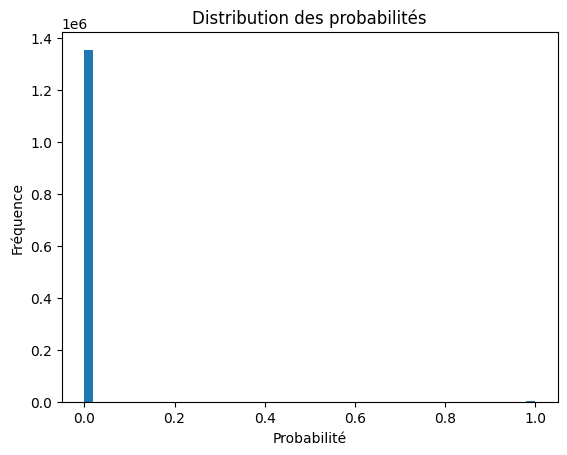

Mean: 0.0017802007108313536
Std: 0.03929265132690487


In [54]:
#LGBM
plt.hist(y_prob.flatten(), bins=50)
plt.title("Distribution des probabilités")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

print("Mean:", np.mean(y_prob))
print("Std:", np.std(y_prob))

In [55]:
# On compare avec un modèle aléatoire
import numpy as np
from sklearn.metrics import f1_score

# prédictions aléatoires
y_random = np.random.randint(0, 2, size=y_test.shape)

f1_random = f1_score(y_test, y_random, average="macro")
print("F1 aléatoire :", f1_random)

F1 aléatoire : 0.00955631316481519


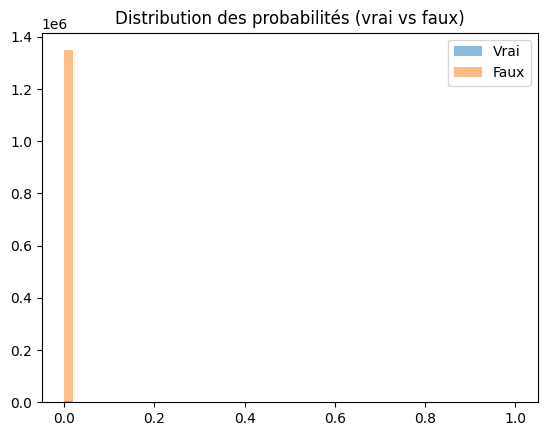

In [56]:
true_probs = y_prob[y_test == 1]
false_probs = y_prob[y_test == 0]

plt.hist(true_probs, bins=50, alpha=0.5, label="Vrai")
plt.hist(false_probs, bins=50, alpha=0.5, label="Faux")
plt.legend()
plt.title("Distribution des probabilités (vrai vs faux)")
plt.show()

In [5]:
### Model LGBM
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

# Environ 23 min
model_LGBM = OneVsRestClassifier(
    LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=64,
        n_jobs=-1
    )
)

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011601 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000304 -> initscore=-8.099782
[LightGBM] [Info] Start training from score -8.099782
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.07613554990419023


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
print("F1-score:", f1_LGBM)

F1-score: 0.07613554990419023


Vérifie que la somme est égale à 1 :  1.0
mean 0.018758641856632747
std 0.020171615027740283
min 0.01945373775744887
max 0.018539082281255025


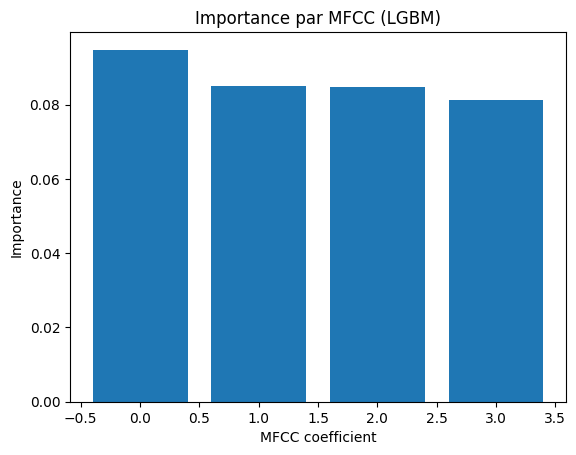

In [6]:
# Visualisation de l'importance de la MFCC (LGBM)
import numpy as np
import matplotlib.pyplot as plt

model = model_LGBM

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 4
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

In [7]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=10, max_depth=5, n_jobs=-1))
# 1h
model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.011821222194362022


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Vérifie que la somme est égale à 1 :  1.0
mean 0.018641306975637314
std 0.020151931029803595
min 0.019008264743333458
max 0.01912157417430256


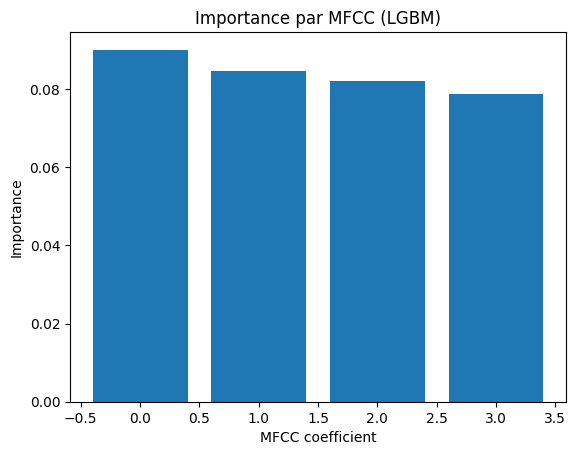

In [9]:
# Visualisation de l'importance de la MFCC (LGBM)
import numpy as np
import matplotlib.pyplot as plt

model = model_forest

importances = np.mean(
    [est.feature_importances_ for est in model.estimators_],
    axis=0
)

n_mfcc = 4
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

In [ ]:
# ============================
# Avec pondération des classes
# ============================

In [31]:
# LGBM avec pondération des classes
# Un peu tard, j'aurais dû y penser avant
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))

print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.016565 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13260
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.14248956477448066


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [32]:
print("F1-score:", f1_LGBM)

F1-score: 0.14248956477448066


In [9]:
# Poids des exemples LGBM
import numpy as np

n_classes = y_train.shape[1]

weights = {}

for i in range(n_classes):

    positives = np.sum(y_train[:, i] == 1)
    negatives = np.sum(y_train[:, i] == 0)

    if positives > 0:
        weight = negatives / positives
    else:
        weight = 0

    weights[i] = weight

# afficher quelques poids
for k in list(weights.keys())[:10]:
    print(f"Classe {k}: poids = {weights[k]:.2f}")

Classe 0: poids = 3293.75
Classe 1: poids = 26357.00
Classe 2: poids = 2195.50
Classe 3: poids = 6588.50
Classe 4: poids = 26357.00
Classe 5: poids = 8785.00
Classe 6: poids = 975.22
Classe 7: poids = 5270.60
Classe 8: poids = 3293.75
Classe 9: poids = 536.92


In [10]:
# Poids des exemples rares LGBM
sorted_weights = sorted(weights.items(), key=lambda x: x[1], reverse=True)

for c, w in sorted_weights[:10]:
    print(f"Classe rare {c} ({le.classes_[c]}): poids = {w:.1f}")

Classe rare 1 (116570): poids = 26357.0
Classe rare 4 (209233): poids = 26357.0
Classe rare 12 (23150): poids = 26357.0
Classe rare 16 (23724): poids = 26357.0
Classe rare 29 (516975): poids = 26357.0
Classe rare 33 (64898): poids = 26357.0
Classe rare 20 (24321): poids = 13178.0
Classe rare 28 (476521): poids = 13178.0
Classe rare 30 (555123): poids = 13178.0
Classe rare 39 (70711): poids = 13178.0


In [33]:
y_prob = model_LGBM.predict_proba(X_test)

print("Mean:", y_prob.mean())
print("Std:", y_prob.std())
print("Max:", y_prob.max())

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Mean: 0.0027265787284194536
Std: 0.03108390520942927
Max: 0.9999735044188935


In [34]:
print("Mean:", y_prob.mean())
print("Std:", y_prob.std())
print("Max:", y_prob.max())

Mean: 0.0027265787284194536
Std: 0.03108390520942927
Max: 0.9999735044188935


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

Nombre de vrais : 6590
Nombre de faux : 1350950


(array([4.92573204e+01, 3.17569714e-01, 1.22549338e-01, 7.04353340e-02,
        4.56367666e-02, 2.98693192e-02, 2.32070175e-02, 1.91356110e-02,
        1.45090126e-02, 1.15850024e-02, 9.47527351e-03, 8.92008170e-03,
        7.47658300e-03, 5.84802037e-03, 5.62594365e-03, 4.88568790e-03,
        4.03439380e-03, 4.14543216e-03, 2.81297182e-03, 2.44284395e-03,
        2.40583116e-03, 3.14608691e-03, 2.07271608e-03, 1.81362657e-03,
        1.66557542e-03, 2.29479280e-03, 1.77661378e-03, 1.85063936e-03,
        1.29544755e-03, 1.07337083e-03, 9.62332466e-04, 1.18440919e-03,
        1.18440919e-03, 1.22142198e-03, 1.14739640e-03, 7.40255743e-04,
        8.51294105e-04, 7.77268530e-04, 8.14281317e-04, 6.29217382e-04,
        7.40255743e-04, 2.59089510e-04, 4.81166233e-04, 4.81166233e-04,
        6.66230169e-04, 5.55191807e-04, 7.03242956e-04, 6.29217382e-04,
        3.70127872e-04, 1.14739640e-03]),
 array([8.31218481e-07, 1.99998613e-02, 3.99988915e-02, 5.99979216e-02,
        7.99969517e-02

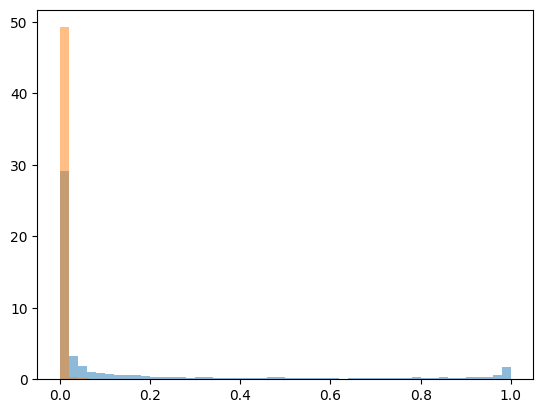

In [37]:
model = model_LGBM
y_proba = model.predict_proba(X_test)

true_probas = y_proba[y_test == 1]


print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

# Probabilités pour les faux labels (négatifs)
false_probas = y_proba[y_test == 0]

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

Nombre de vrais : 6590
Nombre de faux : 1350950


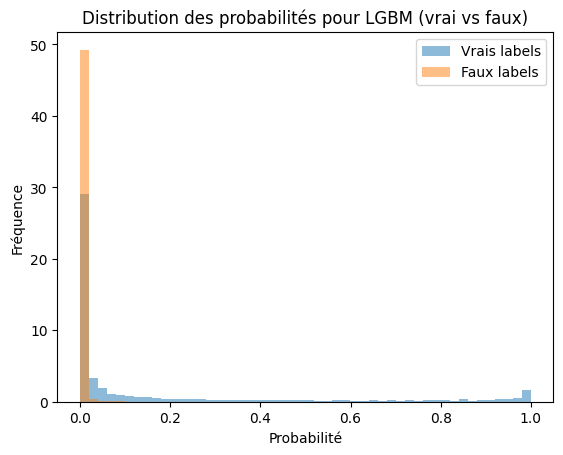

In [38]:
# Pour améliorer la lisibilité (LGBM)
print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour LGBM (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

In [30]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.06302700948909523


In [20]:
y_prob = model_forest.predict_proba(X_test)

print("Mean:", y_prob.mean())
print("Std:", y_prob.std())
print("Max:", y_prob.max())

Mean: 0.30099429016210705
Std: 0.14950590230820815
Max: 1.0


Nombre de vrais : 6590
Nombre de faux : 1350950


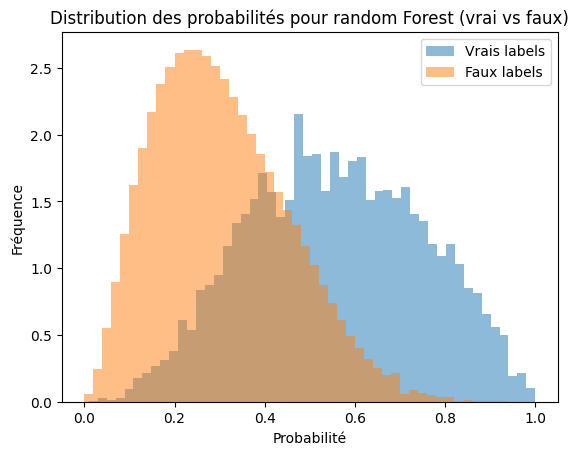

In [39]:
# Distribution des probabilités pour les vrais positifs et les faux positifs (BalancedRandomForestClassifier)
import matplotlib.pyplot as plt

model = model_forest
y_proba = model_forest.predict_proba(X_test)

true_probas = y_proba[y_test == 1]


print("Nombre de vrais :", np.sum(y_test == 1))
print("Nombre de faux :", np.sum(y_test == 0))

# Probabilités pour les faux labels (négatifs)
false_probas = y_proba[y_test == 0]

plt.hist(true_probas, bins=50, alpha=0.5, label="Vrais labels", density=True)
plt.hist(false_probas, bins=50, alpha=0.5, label="Faux labels", density=True)

plt.legend()
plt.title("Distribution des probabilités pour random Forest (vrai vs faux)")
plt.xlabel("Probabilité")
plt.ylabel("Fréquence")
plt.show()

In [ ]:
# ====
# PCA
# ====

In [123]:
# MFCC 13
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 90%
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Shape avant :", X.shape)
print("Shape après :", X_pca.shape)
print("Variance conservée :", pca.explained_variance_ratio_.sum())

Shape avant : (32948, 52)
Shape après : (32948, 15)
Variance conservée : 0.9077234396167374


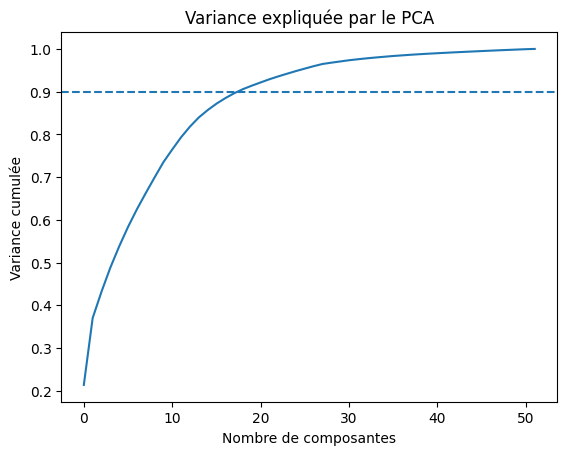

In [24]:


import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cum_var)
plt.axhline(0.90, linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.title("Variance expliquée par le PCA")
plt.show()

In [36]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003266 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4845
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003079 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4845
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.13632189635056108


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
print("F1-score:", f1_LGBM)

F1-score: 0.13632189635056108


In [124]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


KeyboardInterrupt: 

In [56]:
# Delta 1 et 2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 90%
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Shape avant :", X.shape)
print("Shape après :", X_pca.shape)
print("Variance conservée :", pca.explained_variance_ratio_.sum())

Shape avant : (32948, 156)
Shape après : (32948, 50)
Variance conservée : 0.900096315077846


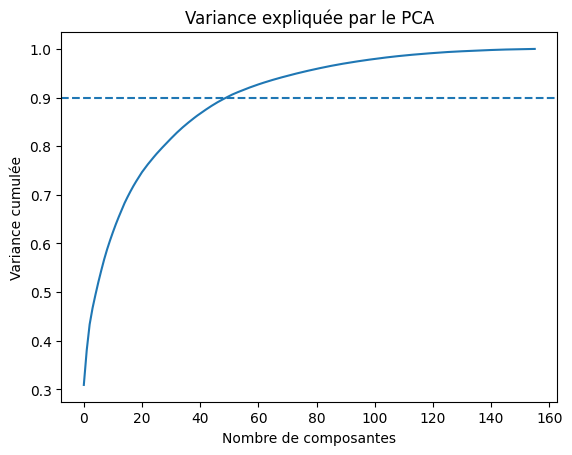

In [5]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cum_var)
plt.axhline(0.90, linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.title("Variance expliquée par le PCA")
plt.show()

In [ ]:


# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y_encoded,
    test_size=0.2,
    random_state=13
)

In [137]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002323 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3825
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 32, number of negative: 26326
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002316 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3825
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 15, number of negative: 26343
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002314 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3825
[LightGBM] [Info] Nu

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 2, number of negative: 26356
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002329 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3825
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.11686404327715894


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [138]:
print("F1-score:", f1_LGBM)

F1-score: 0.11686404327715894


In [139]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score


print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.05415529242199654


In [ ]:
# ======================
# Descripteur spectraux
# ======================

In [1]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 13


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        # On utilise la représentation MFCC parce que c'est rapide et efficace
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        zcr = librosa.feature.zero_crossing_rate(y)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)

        features = np.concatenate([summarize_feature(mfcc),summarize_feature(zcr),summarize_feature(centroid),summarize_feature(rolloff)])
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None


train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [21:28<00:00, 27.59it/s]


Extraction des features terminée !
Shape X: (32948, 64)


In [27]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=13
)

In [15]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009934 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 16320
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012071 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 16320
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.15789676101836958


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [16]:
print("F1-score:", f1_LGBM)

F1-score: 0.15789676101836958


In [17]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.0632581684696149


In [13]:
import numpy as np

valid_estimators = [
    est for est in model_LGBM.estimators_
    if hasattr(est, "feature_importances_")
]

print("Nombre de modèles valides :", len(valid_estimators))
print("Nombre total de classes :", len(model_LGBM.estimators_))

importances = np.mean(
    [est.feature_importances_ for est in valid_estimators],
    axis=0
)

mfcc_imp = importances[:52].sum()
zcr_imp = importances[52:56].sum()
centroid_imp = importances[56:60].sum()
rolloff_imp = importances[60:64].sum()

somme = mfcc_imp + zcr_imp + centroid_imp + rolloff_imp

print("MFCC:", mfcc_imp/somme)
print("ZCR:", zcr_imp/somme)
print("Centroid:", centroid_imp/somme)
print("Rolloff:", rolloff_imp/somme)

Nombre de modèles valides : 204
Nombre total de classes : 206
MFCC: 0.848148681287831
ZCR: 0.05522502367979667
Centroid: 0.043144549749841145
Rolloff: 0.0534817452825312


In [18]:
import numpy as np

valid_estimators = [
    est for est in model_forest.estimators_
    if hasattr(est, "feature_importances_")
]

print("Nombre de modèles valides :", len(valid_estimators))
print("Nombre total de classes :", len(model_forest.estimators_))

importances = np.mean(
    [est.feature_importances_ for est in valid_estimators],
    axis=0
)

mfcc_imp = importances[:52].sum()
zcr_imp = importances[52:56].sum()
centroid_imp = importances[56:60].sum()
rolloff_imp = importances[60:64].sum()

somme = mfcc_imp + zcr_imp + centroid_imp + rolloff_imp

print("MFCC:", mfcc_imp/somme)
print("ZCR:", zcr_imp/somme)
print("Centroid:", centroid_imp/somme)
print("Rolloff:", rolloff_imp/somme)

Nombre de modèles valides : 205
Nombre total de classes : 206
MFCC: 0.8363703982538012
ZCR: 0.05845253627428876
Centroid: 0.05484869147241424
Rolloff: 0.05032837399949579


In [19]:
feature_names = []

# MFCC
for stat in ["mean", "std", "min", "max"]:
    for i in range(13):
        feature_names.append(f"{stat}_mfcc_{i}")

# ZCR
for stat in ["mean", "std", "min", "max"]:
    feature_names.append(f"{stat}_zcr")

# Centroid
for stat in ["mean", "std", "min", "max"]:
    feature_names.append(f"{stat}_centroid")

# Rolloff
for stat in ["mean", "std", "min", "max"]:
    feature_names.append(f"{stat}_rolloff")

print(len(feature_names))

64


In [20]:
import pandas as pd

df = pd.DataFrame(X, columns=feature_names)

corr = df.corr().abs()

/tmp/ipykernel_57/1093686665.py:6: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = linkage(


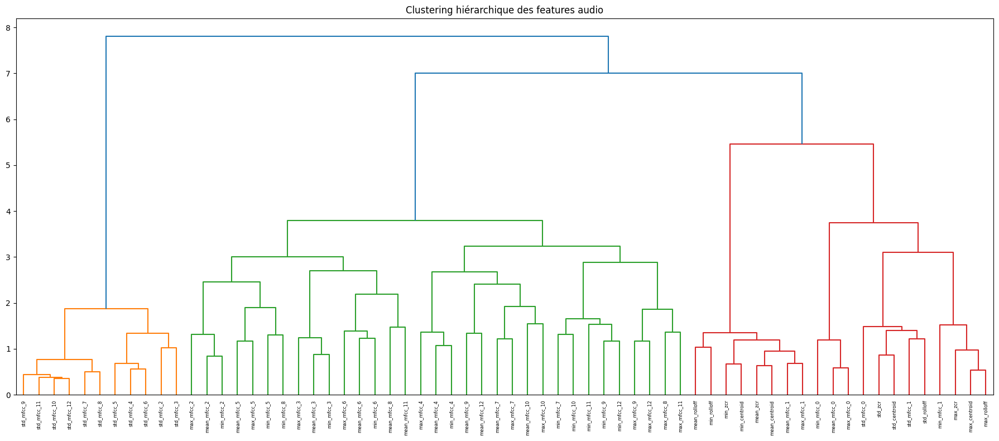

In [21]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

distance = 1 - corr

linkage_matrix = linkage(
    distance,
    method="ward"
)

plt.figure(figsize=(18, 8))

dendrogram(
    linkage_matrix,
    labels=feature_names,
    leaf_rotation=90
)

plt.title("Clustering hiérarchique des features audio")
plt.tight_layout()
plt.show()

In [25]:
from scipy.cluster.hierarchy import fcluster

clusters = fcluster(
    linkage_matrix,
    t=3,
    criterion="maxclust"
)

cluster_dict = {}

for feature, cluster in zip(feature_names, clusters):
    cluster_dict.setdefault(cluster, []).append(feature)

for cluster, feats in cluster_dict.items():
    print("\nCluster", cluster)
    for f in feats:
        print(f)


Cluster 3
mean_mfcc_0
mean_mfcc_1
std_mfcc_0
std_mfcc_1
min_mfcc_0
min_mfcc_1
max_mfcc_0
max_mfcc_1
mean_zcr
std_zcr
min_zcr
max_zcr
mean_centroid
std_centroid
min_centroid
max_centroid
mean_rolloff
std_rolloff
min_rolloff
max_rolloff

Cluster 2
mean_mfcc_2
mean_mfcc_3
mean_mfcc_4
mean_mfcc_5
mean_mfcc_6
mean_mfcc_7
mean_mfcc_8
mean_mfcc_9
mean_mfcc_10
mean_mfcc_11
mean_mfcc_12
min_mfcc_2
min_mfcc_3
min_mfcc_4
min_mfcc_5
min_mfcc_6
min_mfcc_7
min_mfcc_8
min_mfcc_9
min_mfcc_10
min_mfcc_11
min_mfcc_12
max_mfcc_2
max_mfcc_3
max_mfcc_4
max_mfcc_5
max_mfcc_6
max_mfcc_7
max_mfcc_8
max_mfcc_9
max_mfcc_10
max_mfcc_11
max_mfcc_12

Cluster 1
std_mfcc_2
std_mfcc_3
std_mfcc_4
std_mfcc_5
std_mfcc_6
std_mfcc_7
std_mfcc_8
std_mfcc_9
std_mfcc_10
std_mfcc_11
std_mfcc_12


In [26]:
# zcr + centroid + rolloff
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 90%
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Shape avant :", X.shape)
print("Shape après :", X_pca.shape)
print("Variance conservée :", pca.explained_variance_ratio_.sum())

Shape avant : (32948, 64)
Shape après : (32948, 22)
Variance conservée : 0.9037026034635043


In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cum_var)
plt.axhline(0.90, linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.title("Variance expliquée par le PCA")
plt.show()

In [36]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=13
)

In [37]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012576 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 16320
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 32, number of negative: 26326
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010531 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 16320
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 15, number of negative: 26343
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the ove

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 2, number of negative: 26356
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004054 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 16320
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.14789486230002286


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
print("F1-score:", f1_LGBM)

In [30]:
# Model BalancedRandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.06361563256813532


In [ ]:
# =========
# MFCC = 30
# =========

In [39]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=7
)

In [40]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 9, number of negative: 26349
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.021393 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 30600
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 120
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3, number of negative: 26355
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022468 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 30600
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 120
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.16037297213977547


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
print("F1-score:", f1_LGBM)

F1-score: 0.16037297213977547


Nombre de modèles valides : 205
Nombre total de classes : 206
Vérifie que la somme est égale à 1 :  1.0000000000000002
mean 0.007817213491941895
std 0.007908534691960529
min 0.00915807792100162
max 0.008449507228429293


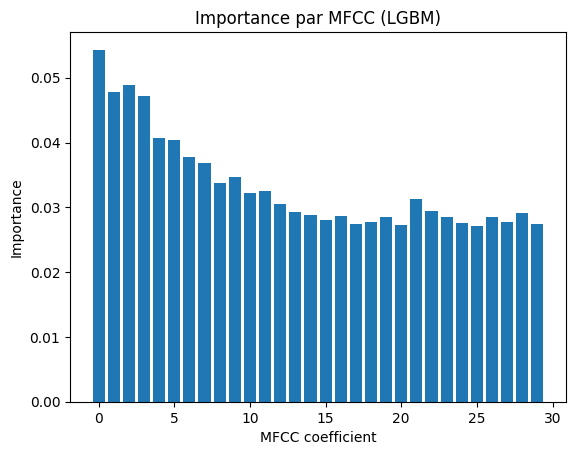

In [47]:
# Visualisation de l'importance de la MFCC (LGBM)
import numpy as np
import matplotlib.pyplot as plt

model = model_LGBM

valid_estimators = [
    est for est in model.estimators_
    if hasattr(est, "feature_importances_")
]

print("Nombre de modèles valides :", len(valid_estimators))
print("Nombre total de classes :", len(model.estimators_))

importances = np.mean(
    [est.feature_importances_ for est in valid_estimators],
    axis=0
)

n_mfcc = 30
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

In [34]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(
 60%|██████    | 21431/35549 [1:23:53<55:16,  4.26it/s]


Predictions
F1-score: 0.07701057854671575


Nombre de modèles valides : 204
Nombre total de classes : 206
Vérifie que la somme est égale à 1 :  1.0
mean 0.007374283700727607
std 0.009099180996223668
min 0.008543619723423736
max 0.00831624891295832


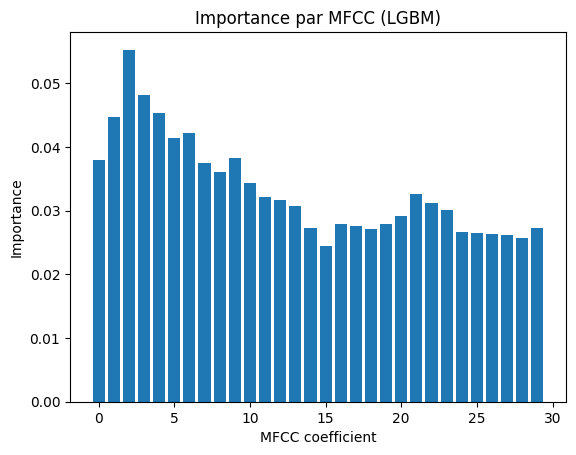

In [48]:
# Visualisation de l'importance de la MFCC (BRF)
import numpy as np
import matplotlib.pyplot as plt

model = model_forest

valid_estimators = [
    est for est in model.estimators_
    if hasattr(est, "feature_importances_")
]

print("Nombre de modèles valides :", len(valid_estimators))
print("Nombre total de classes :", len(model.estimators_))

importances = np.mean(
    [est.feature_importances_ for est in valid_estimators],
    axis=0
)

n_mfcc = 30
block_size = len(importances) // 4  # mean/std/min/max

mfcc_importance = np.zeros(n_mfcc)
importances = importances / np.sum(importances)
print("Vérifie que la somme est égale à 1 : ", np.sum(importances))

for i in range(n_mfcc):
    mfcc_importance[i] = (
        importances[i] +                        # mean
        importances[i + block_size] +          # std
        importances[i + 2*block_size] +        # min
        importances[i + 3*block_size]          # max
    )

groups = {
    "mean": importances[:block_size],
    "std": importances[block_size:2*block_size],
    "min": importances[2*block_size:3*block_size],
    "max": importances[3*block_size:]
}

for k, v in groups.items():
    print(k, np.mean(v))

plt.bar(range(n_mfcc), mfcc_importance)
plt.xlabel("MFCC coefficient")
plt.ylabel("Importance")
plt.title("Importance par MFCC (LGBM)")
plt.show()

In [49]:
# MFCC 30
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 90%
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Shape avant :", X.shape)
print("Shape après :", X_pca.shape)
print("Variance conservée :", pca.explained_variance_ratio_.sum())



Shape avant : (32948, 120)
Shape après : (32948, 40)
Variance conservée : 0.9001680065350248


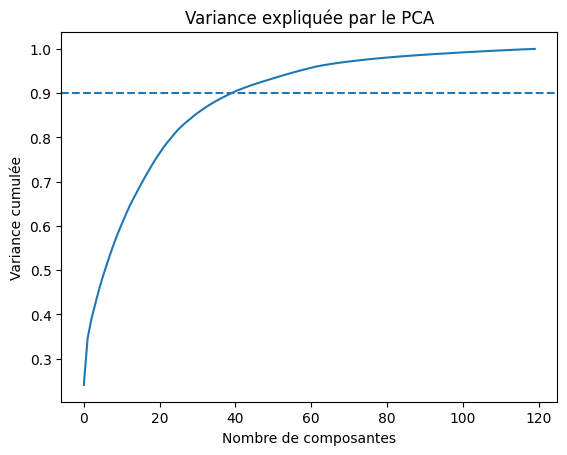

In [50]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cum_var)
plt.axhline(0.90, linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.title("Variance expliquée par le PCA")
plt.show()



In [57]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y_encoded,
    test_size=0.2,
    random_state=13
)

In [58]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014530 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 10200
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 40
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Number of positive: 32, number of negative: 26326
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006492 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 10200
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 40
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007632 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 10200
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 40
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.15602121532188742


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [59]:
print("F1-score:", f1_LGBM)

F1-score: 0.15602121532188742


In [61]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 16 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 29 is present in all training examples.
  warnings.warn(


Predictions
F1-score: 0.08653442614340613


In [ ]:
# =================
# Le combo gagnant
# =================

In [62]:
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed
import os
import pickle


# Paramètres des fichiers audio
SR = 32000
DURATION = 5  # secondes
N_MFCC = 30


# Permet de collecter les données et faire du feature engineering
def summarize_feature(feature):
    return np.concatenate([
        np.mean(feature, axis=1),
        np.std(feature, axis=1),
        np.min(feature, axis=1),
        np.max(feature, axis=1)
    ])

# Segmentation des audio
def split_audio(y, sr, segment_seconds=5):

    segment_length = sr * segment_seconds

    segments = []

    for start in range(0, len(y), segment_length):

        segment = y[start:start+segment_length]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

# Extraction des features
def extract_features(path):
    try:
        # Chargement rapide
        y, sr = sf.read(path)

        # Convertir en mono si nécessaire
        if len(y.shape) > 1:
            y = np.mean(y, axis=1)

        # Transforme les audio qui ne seraient pas à 32000 Hz
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
            sr = SR

        # Garder seulement les 5 premières secondes
        y = y[:sr * DURATION]

        # On skip les fichiers qui sont trop courts
        if len(y) < sr * DURATION:
            return None

        # On utilise la représentation MFCC parce que c'est rapide et efficace
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        delta = librosa.feature.delta(mfcc)
        delta2 = librosa.feature.delta(mfcc, order=2)
        zcr = librosa.feature.zero_crossing_rate(y)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)

        features = np.concatenate([summarize_feature(mfcc), summarize_feature(delta),summarize_feature(delta2),summarize_feature(zcr),summarize_feature(centroid),summarize_feature(rolloff)])
        #features = np.concatenate([summarize_feature(mfcc)])
        return features

    # Au cas où, on skip les fichiers qui ont des erreurs
    except Exception as e:
        return None


train = pd.read_csv("/kaggle/input/competitions/birdclef-2026/train.csv")

# TEST RAPIDE (à enlever plus tard)
#train = train.sample(5000, random_state=42)


paths = [
    os.path.join("/kaggle/input/competitions/birdclef-2026/train_audio", f)
    for f in train.filename
]


# Multi processing pour accélerer le temps d'execution 
results = Parallel(n_jobs=-1)(
    delayed(extract_features)(p) for p in tqdm(paths)
)


# Nettoyage des données au cas où certains fichiers auraient engendrés des erreurs
X = []
y = []

for feat, label in zip(results, train.primary_label):
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)


# On encode les labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# On sauvegarde les features pour éviter de tous refaire

#with open("X.pkl", "wb") as f:
with open("X_mfcc.pkl", "wb") as f:
    pickle.dump(X, f)

#with open("y.pkl", "wb") as f:
with open("y_mfcc.pkl", "wb") as f:
    pickle.dump(y_encoded, f)

#with open("label_encoder.pkl", "wb") as f:
with open("label_encoder_mfcc.pkl", "wb") as f:
    pickle.dump(le, f)
    

print("Extraction des features terminée !")
print("Shape X:", X.shape)

100%|██████████| 35549/35549 [21:14<00:00, 27.90it/s]


Extraction des features terminée !
Shape X: (32948, 372)


In [75]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, et 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_reduit, y_encoded,
    test_size=0.2,
    random_state=42
)

In [76]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.207861 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 94860
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 372
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wit

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

F1-score: 0.15065996148104863


In [77]:
print("F1-score:", f1_LGBM)

F1-score: 0.15065996148104863


In [78]:
# Model RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import f1_score



print("Modele...")

#model_forest = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1))
model_forest = OneVsRestClassifier(
    BalancedRandomForestClassifier(
        n_estimators=100,
        max_depth=50,
        n_jobs=-1,
        random_state=42
    )
)

print("Entraînement...")
model_forest.fit(X_train, y_train)

print("Predictions")
y_pred = model_forest.predict(X_test)

f1_forest = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_forest)



Modele...
Entraînement...
Predictions
F1-score: 0.07751119706826402


In [79]:
# tous
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 90%
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Shape avant :", X.shape)
print("Shape après :", X_pca.shape)
print("Variance conservée :", pca.explained_variance_ratio_.sum())



Shape avant : (32948, 372)
Shape après : (32948, 124)
Variance conservée : 0.9001339897681779


In [82]:
# Séparation train/test des données
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

X_reduit = X
y_reduit = y

### Pour tester si le code fonctionne
#MAX_SAMPLES = 5000
#X_reduit = X[:MAX_SAMPLES]
#y_reduit = y[:MAX_SAMPLES]


# Pour transformer les point virgules en liste ("oiseau1;oiseau2" -> ["oiseau1","oiseau2"])
y_multi = [label.split(";") if isinstance(label, str) else [label] for label in y_reduit]

# Encodage multi label
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_multi)

# Sépartion train/test (avec seed 42, 13, 7)
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y_encoded,
    test_size=0.2,
    random_state=42
)

In [ ]:
### Model LGBM

# Environ 23 min
model_LGBM =  OneVsRestClassifier(LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=64,
    class_weight="balanced",
    n_jobs=-1
))



print("Entraînement...")
model_LGBM.fit(X_train, y_train)

print("Prédictions...")
y_pred = model_LGBM.predict(X_test)

f1_LGBM = f1_score(y_test, y_pred, average="macro")
print("F1-score:", f1_LGBM)

Entraînement...
[LightGBM] [Info] Number of positive: 8, number of negative: 26350
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.033088 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 31620
[LightGBM] [Info] Number of data points in the train set: 26358, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wit